<a href="https://colab.research.google.com/github/mehmoodanas/Bootcamp/blob/main/Day4/Day4_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu
* when you are making plots, please add labels to the axes

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans
# you will need to import more libraries as needed

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [7]:
import pandas as pd

customer_data = pd.read_csv('shopping-data.csv')

In [8]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [9]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
# Changing the column name
customer_data = customer_data.rename(columns={'Genre': 'Gender'})
customer_data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

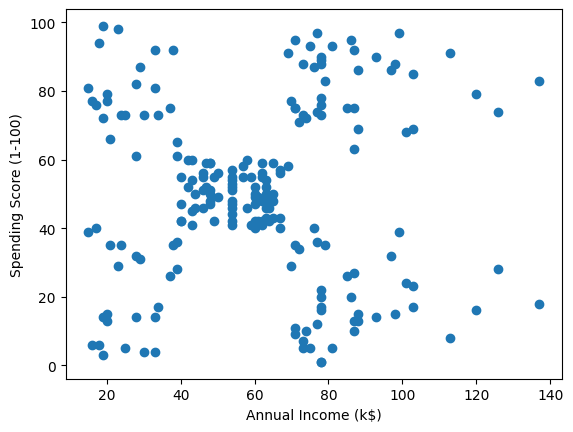

In [40]:
income = customer_data['Annual Income (k$)']
spending = customer_data['Spending Score (1-100)']

plt.scatter(income, spending)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

#### 3. Normalize the data

In [42]:
X = customer_data[['Annual Income (k$)', 'Spending Score (1-100)']]

# Standardizing
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled[0:10]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002]])

#### 4. Use Elbow method to decide number of clusters

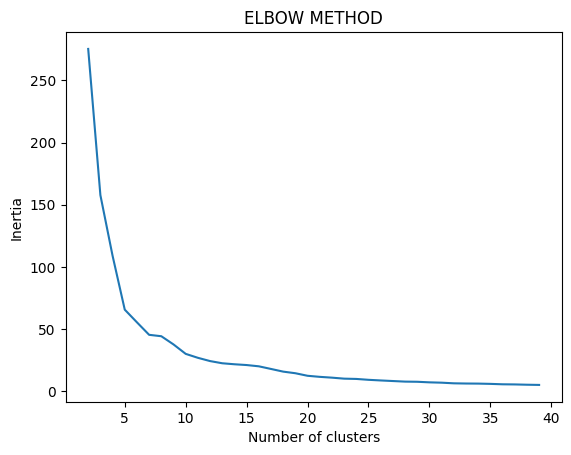

In [55]:
elbow = []
for i in range(2, 40):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=555, max_iter=200)
    kmeans.fit(X_scaled)
    elbow.append(kmeans.inertia_)

plt.plot(range(2, 40), elbow)
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('ELBOW METHOD')
plt.show()

#### 5. Perform Clustering using KMeans

In [61]:
k = 5

Cluster = KMeans(n_clusters=k, max_iter=200, random_state=555)
Cluster.fit(X_scaled)

y_pred = Cluster.predict(X_scaled)
y_pred

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 2,
       3, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 1, 0, 2, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 2, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0], dtype=int32)

#### 6. Plot scatter plot and color code in clustered groups

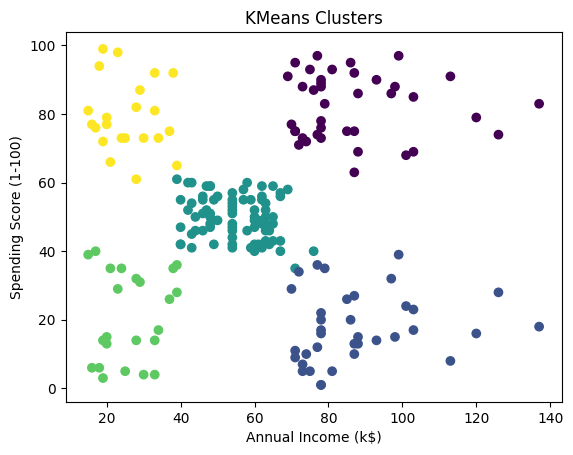

In [63]:
plt.scatter(income, spending, c=y_pred)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('KMeans Clusters')
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

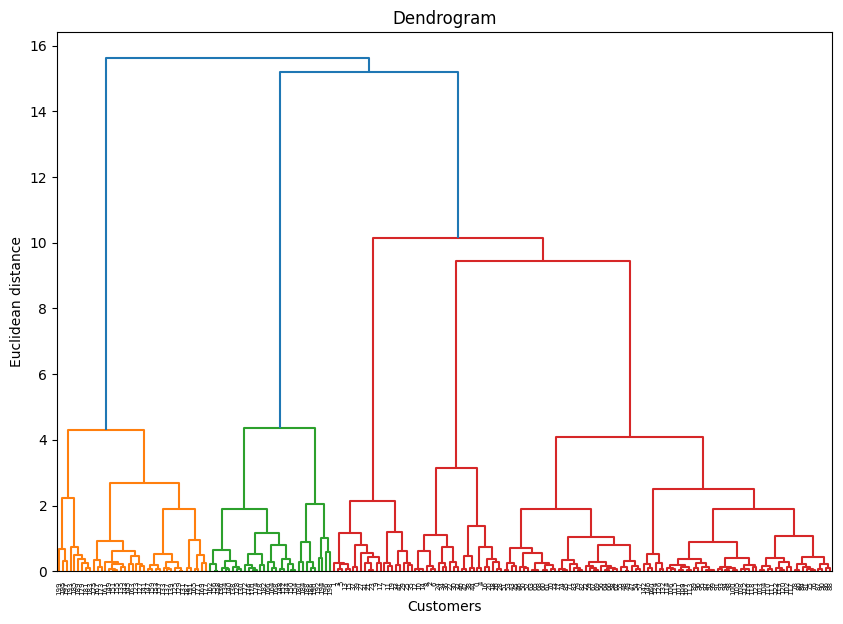

In [65]:
import scipy.cluster.hierarchy as shc

# Plot the dendrogram
plt.figure(figsize=(10, 7))
plt.title("Dendrogram")
dend = shc.dendrogram(shc.linkage(X_scaled, method='ward'))
plt.xlabel('Customers')
plt.ylabel('Euclidean distance')
plt.show()

So, basically, the best number of clusters is 5. Basically, in the dendrogram, there is a big empty space. Actually, this space is between about 4.4 and 9.5. In this space, actually, no groups join. So, basically, the groups are very different.
Basically, we draw one line in this space. Actually, the line is at about 7. So, the line cuts 5 lines. Basically, this means we have 5 groups.
Actually, the groups under the line are very close. Basically, the groups over the line are very far. So, actually, the groups are really different.


#### 8. Do clustering using Hierarchical Clustering

In [66]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X_scaled)
y_hc

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 2,
       4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 1, 0, 1, 0, 1,
       2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1])

#### 9. Plot scatter plot and color code in clustered groups

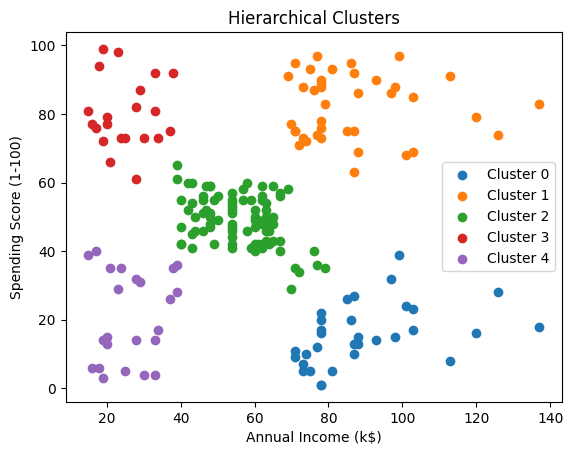

In [67]:
# Scatter plot colored by hierarchical cluster
for i in range(5):
    plt.scatter(income[y_hc == i], spending[y_hc == i], label='Cluster ' + str(i))

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hierarchical Clusters')
plt.legend()
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [68]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

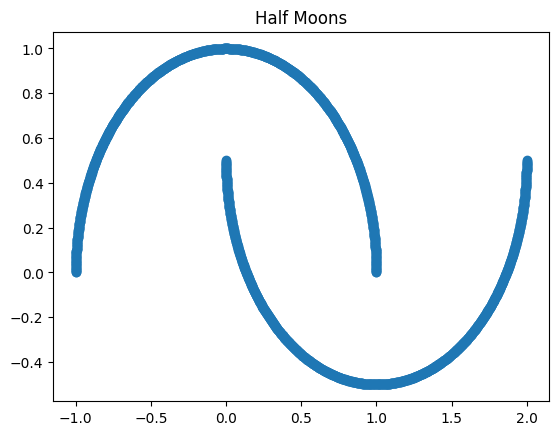

In [69]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [72]:
kmeans_moons = KMeans(n_clusters=2, max_iter=200, random_state=555)
kmeans_moons.fit(moons_X)
y_kmeans = kmeans_moons.predict(moons_X)

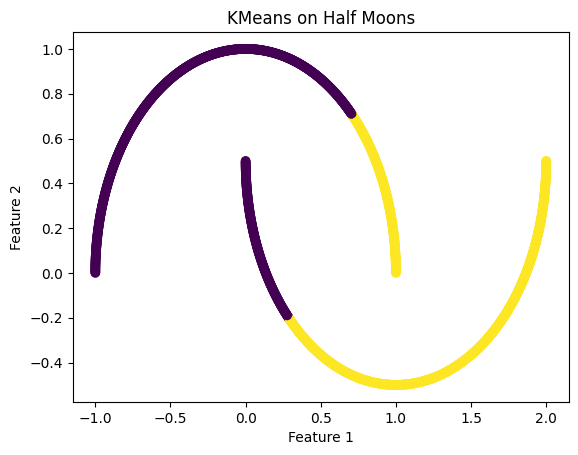

In [73]:
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=y_kmeans)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('KMeans on Half Moons')
plt.show()



#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [74]:
from sklearn.cluster import DBSCAN

model = DBSCAN(eps=0.2, min_samples=5)

yhat = model.fit_predict(moons_X)

clusters = np.unique(yhat)
clusters

array([0, 1])

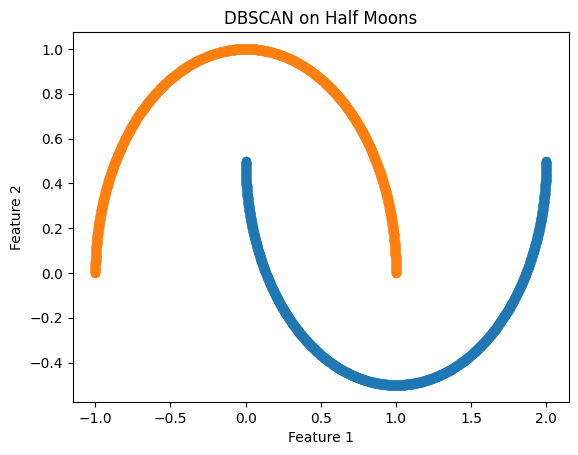

In [75]:
# Create scatter plot for samples from each cluster
for cluster in clusters:
    row_ix = np.where(yhat == cluster)
    plt.scatter(moons_X[row_ix, 0], moons_X[row_ix, 1])

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('DBSCAN on Half Moons')
plt.show()

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

With KMeans, the two moons were actually not separated correctly. KMeans cut the data into two halves with a straight line, so each group has a part of both moons. Basically, KMeans looks for the center of each group and puts every point in the group with the nearest center. This works well when the groups are round, but the moons are curved.

With DBSCAN, each moon became its own group. DBSCAN does not use centers. It connects points that are close to each other, step by step, so it can actually follow the curved shape of each moon. There is a gap between the two moons, so DBSCAN keeps them apart.

I also saw some differences between the two methods. For KMeans, I had to say the number of groups, which was 2. DBSCAN basically found the 2 groups by itself, but I had to choose eps and min_samples instead. When eps was too big, for example 0.6, DBSCAN joined both moons into one group.

So for this data, DBSCAN actually worked better than KMeans, because the groups have a curved shape.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [23]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [77]:
print(penguins.shape)

penguins.describe()

(344, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


#### Based on dataframe describe, in own words explain any abnormal characteristics

So basically, the data has 344 rows, but the count in describe is 342. This means 2 values are missing in each number column.

The flipper length column is actually not normal. The min value is −132. A length cannot be negative, so this is a mistake. The max value is 5000 mm, which is 5 meters, and a penguin cannot have a flipper this long. Most penguins have a flipper length between 190 and 214 mm, which are the 25% and 75% values.

The std of flipper length is 260.6. This is very big, and it is actually even bigger than the mean of 214.0. This happens because of the two wrong values, because they pull the numbers far away from the normal values.

The other columns basically look normal. Their min and max values are possible for penguins.

#### 14. Explore corrupted data

In [78]:
# Number of missing values in each column
print(penguins.isnull().sum())

# Rows that have at least one missing value
null_data = penguins[penguins.isnull().any(axis=1)]
print(null_data.shape)
null_data

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64
(9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [79]:

penguins['sex'].value_counts()

,count
sex,
MALE,169
FEMALE,165
.,1


In [80]:

anomal_rows = penguins.loc[
    (penguins['flipper_length_mm'] < 0) |
    (penguins['flipper_length_mm'] > 300) |
    (penguins['sex'] == '.')
]
anomal_rows

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE
336,44.5,15.7,217.0,4875.0,.


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [81]:
# cleaning
penguins_clean = penguins.dropna()

penguins_clean = penguins_clean.loc[
    (penguins_clean['sex'] != '.') &
    (penguins_clean['flipper_length_mm'] > 0) &
    (penguins_clean['flipper_length_mm'] < 300)
]

print(penguins_clean.shape)
penguins_clean.head()

(332, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [82]:

num_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

scaler_penguins = StandardScaler()
X_penguins = scaler_penguins.fit_transform(penguins_clean[num_cols])

X_penguins[0:5]

array([[-0.90390586,  0.79035987, -1.42534179, -0.56694801],
       [-0.83043377,  0.12618674, -1.0685765 , -0.50484747],
       [-0.68348959,  0.43272819, -0.42639899, -1.18795343],
       [-1.34473838,  1.09690132, -0.5691051 , -0.93955126],
       [-0.86716981,  1.76107445, -0.78316427, -0.6911491 ]])

In [83]:

y_penguins = penguins_clean['sex']
y_penguins.value_counts()

,count
sex,
MALE,167
FEMALE,165


#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

So basically, I removed all rows with missing values or wrong values. In total, I removed 12 rows. There were 2 rows with no data at all, 7 rows with no sex, 1 row with “.” as sex, and 2 rows with an impossible flipper length of −132 and 5000. The data now has 332 rows. Before, it had 344 rows.

This way actually has some good points. The data is now clean, and all values are real and possible. PCA does not work with missing values, so I needed to remove them. I lost only 12 of 344 rows, which is about 3.5 percent, so I still have quite a lot of data. I also did not fill in any values myself, so I did not add wrong information.

But this way also has some bad points. I lost some information, because the 7 penguins with no sex still have good body measurements, but I removed them anyway. With less data, the model also has a little bit less to learn from.

I did not fill the missing sex with a value like MALE or FEMALE. If I did that, some penguins would get the wrong sex, and the model would learn from wrong labels. This would make the model less accurate. Instead, in question 20, I use the trained model to predict the sex of these penguins from their body measurements.

#### 16. Perform PCA with 2 components. Plot the results

In [84]:
# Apply PCA to reduce to 2 components
pca = PCA(n_components=2)
X_penguins_pca = pca.fit_transform(X_penguins)

print(f"Shape after PCA: {X_penguins_pca.shape}")
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")

Shape after PCA: (332, 2)
Explained variance ratio: [0.68713344 0.19641564]
Total variance explained: 88.35%


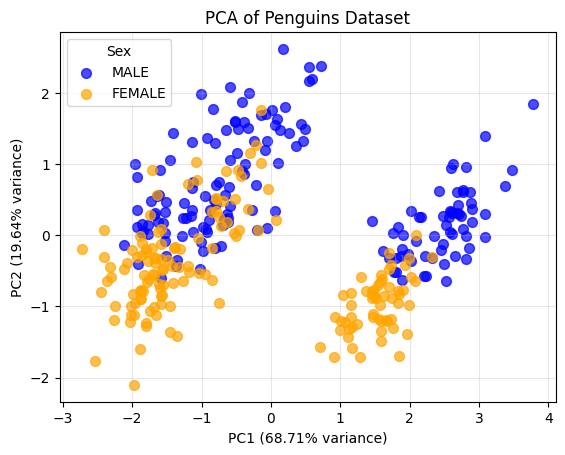

In [85]:
# Plot PCA results, one color for each sex
colors = ['blue', 'orange']
for i, name in enumerate(['MALE', 'FEMALE']):
    plt.scatter(X_penguins_pca[y_penguins == name, 0], X_penguins_pca[y_penguins == name, 1],
                label=name, color=colors[i], s=50, alpha=0.7)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.title('PCA of Penguins Dataset')
plt.legend(title='Sex')
plt.grid(True, alpha=0.3)
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

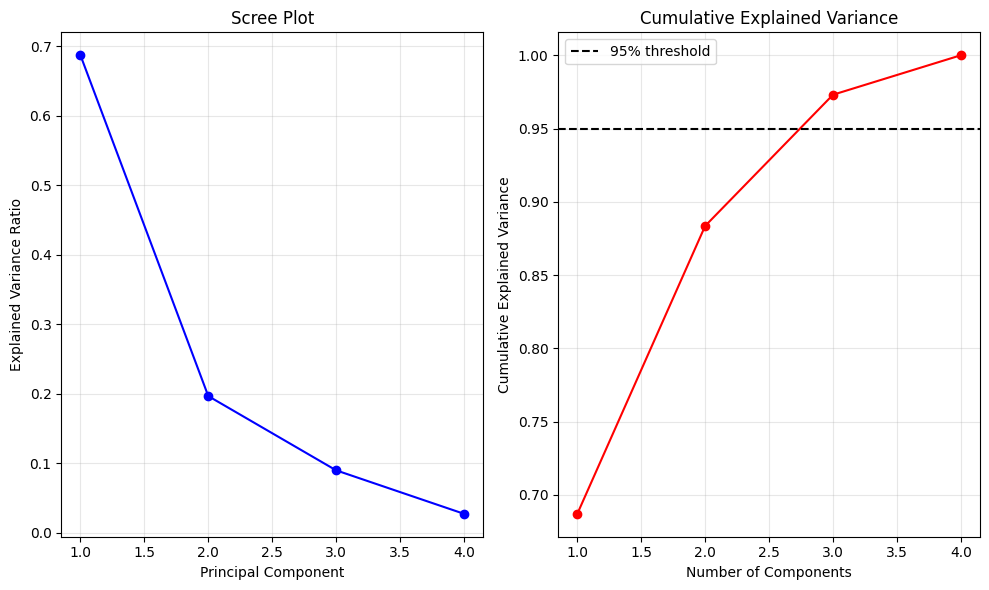

Explained variance by each component:
PC1: 68.71%
PC2: 19.64%
PC3: 8.95%
PC4: 2.69%


In [86]:
pca_full = PCA()
pca_full.fit(X_penguins)


plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         pca_full.explained_variance_ratio_, 'bo-')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         np.cumsum(pca_full.explained_variance_ratio_), 'ro-')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.axhline(y=0.95, color='k', linestyle='--', label='95% threshold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Explained variance by each component:")
for i, var in enumerate(pca_full.explained_variance_ratio_):
    print(f"PC{i+1}: {var:.2%}")

#### 18. Calculate (show in numbers) and display component loadings

In [87]:
components_df = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=num_cols
)

print("Component loadings (feature contributions to PCs):")
components_df

Component loadings (feature contributions to PCs):


,PC1,PC2
culmen_length_mm,0.453174,0.604990
culmen_depth_mm,-0.398518,0.792959
flipper_length_mm,0.576880,0.003798
body_mass_g,0.550478,0.072032


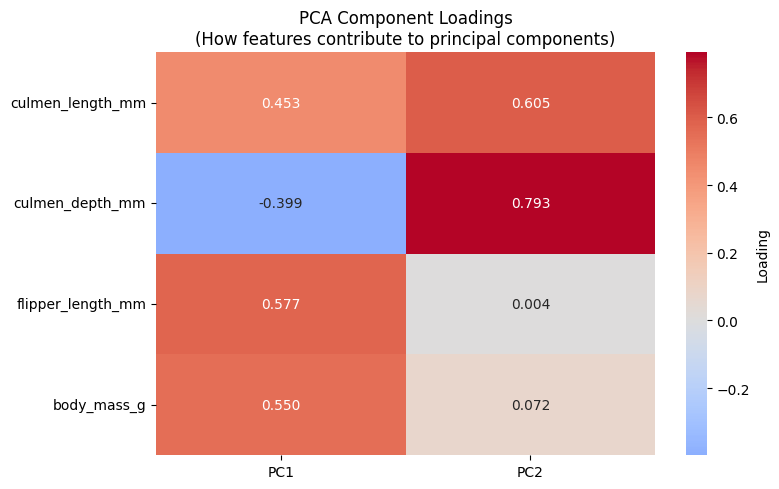

In [88]:
plt.figure(figsize=(8, 5))
sns.heatmap(components_df, annot=True, cmap='coolwarm', center=0,
            cbar_kws={'label': 'Loading'}, fmt='.3f')
plt.title('PCA Component Loadings\n(How features contribute to principal components)')
plt.tight_layout()
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [89]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(X_penguins_pca, y_penguins, test_size=0.3, random_state=101)

# Train a classifier on the PCA data
clf = LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)

# Predict on the test set
y_pred = clf.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.79
              precision    recall  f1-score   support

      FEMALE       0.76      0.77      0.76        44
        MALE       0.82      0.80      0.81        56

    accuracy                           0.79       100
   macro avg       0.79      0.79      0.79       100
weighted avg       0.79      0.79      0.79       100



#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [90]:
# 1. take entries from original data with sex unknown, scale numerical columns
unknown = penguins.loc[(penguins['sex'].isnull()) | (penguins['sex'] == '.')]

unknown = unknown.dropna(subset=num_cols)

X_unknown = scaler_penguins.transform(unknown[num_cols])

print(unknown.shape)
unknown


(8, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
336,44.5,15.7,217.0,4875.0,.


In [91]:
# 2. apply the same PCA transformation to the new data
X_unknown_pca = pca.transform(X_unknown)
X_unknown_pca

array([[-1.84704765, -0.78643204],
       [-1.74324155, -0.79794856],
       [-1.75745513, -0.68276355],
       [-2.64503787, -0.13303451],
       [ 1.16637536, -1.10806084],
       [ 1.58123213, -0.82997265],
       [ 1.92855926, -0.94355846],
       [ 1.45235945, -0.47128001]])

In [92]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
X_train = X_penguins_pca
y_train = y_penguins

# Train a classifier
clf = LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [93]:
# 4. Make predictions on the new data. Display the features and predicted values
unknown['predicted_sex'] = clf.predict(X_unknown_pca)
unknown

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,predicted_sex
8,34.1,18.1,193.0,3475.0,NaN,FEMALE
10,37.8,17.1,186.0,3300.0,NaN,FEMALE
11,37.8,17.3,180.0,3700.0,NaN,FEMALE
47,37.5,18.9,179.0,2975.0,NaN,FEMALE
246,44.5,14.3,216.0,4100.0,NaN,FEMALE
286,46.2,14.4,214.0,4650.0,NaN,FEMALE
324,47.3,13.8,216.0,4725.0,NaN,FEMALE
336,44.5,15.7,217.0,4875.0,.,FEMALE
